In [19]:
#1. Импорт библиотек и выбор устройства (CPU/GPU)

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Автоматический выбор GPU/CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используется устройство: {device}")


Используется устройство: cuda


In [20]:
#2. Настройка путей и проверка классов

import kagglehub

# 1. Скачиваем датасет. Он автоматически загрузится во временное хранилище Colab
dataset_path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Абсолютный путь к датасету в Colab:", dataset_path)

# 2. Настраиваем пути к папкам обучения и теста
TRAIN_DIR = os.path.join(dataset_path, 'seg_train', 'seg_train')
TEST_DIR = os.path.join(dataset_path, 'seg_test', 'seg_test')

classes = sorted(os.listdir(TRAIN_DIR))
print(f"[УСПЕХ] Обнаружено классов: {len(classes)} -> {classes}")

# 3. Настройка продвинутой аугментации данных
IMG_SIZE = 150
BATCH_SIZE = 64

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1), value='random')
])

test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. Инициализация датасетов и лоадеров (для Colab ставим оптимальное число потоков)
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=test_transforms)

num_workers = min(4, multiprocessing.cpu_count())

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=num_workers, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=True)

print(f"Размер тренировочной выборки: {len(train_dataset)} картинок")
print(f"Размер тестовой выборки: {len(test_dataset)} картинок")


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Абсолютный путь к датасету в Colab: /kaggle/input/intel-image-classification
[УСПЕХ] Обнаружено классов: 6 -> ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Размер тренировочной выборки: 14034 картинок
Размер тестовой выборки: 3000 картинок


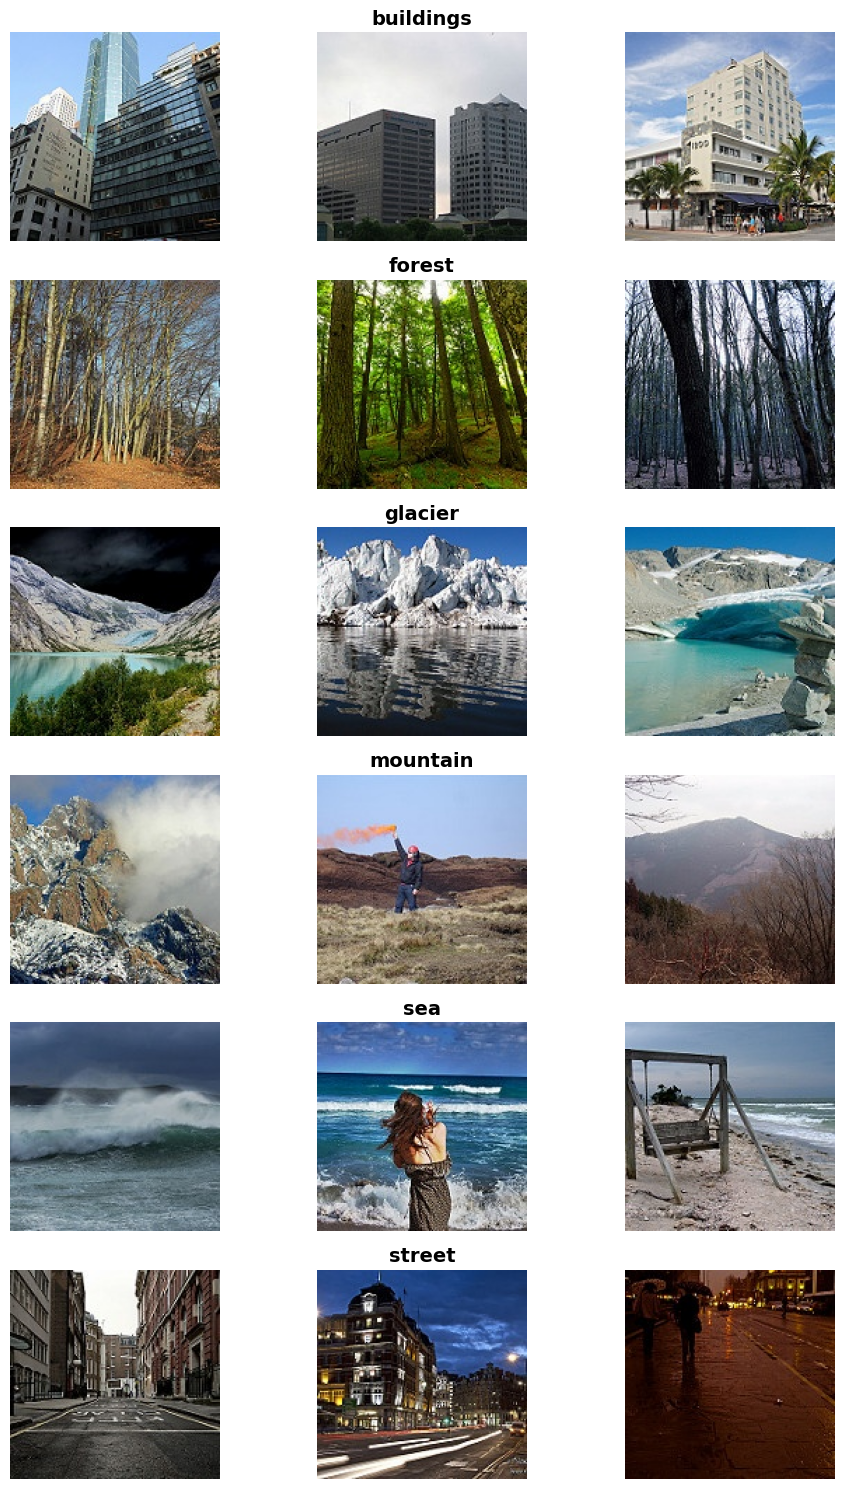

In [21]:
#3. Визуальный анализ данных (EDA) — Вывод случайных изображений

fig, axes = plt.subplots(len(classes), 3, figsize=(10, 15))
for idx, class_name in enumerate(classes):
    class_path = os.path.join(TRAIN_DIR, class_name)
    images = os.listdir(class_path)
    random_imgs = random.sample(images, 3)

    for i, img_name in enumerate(random_imgs):
        img_path = os.path.join(class_path, img_name)
        img = Image.open(img_path)
        axes[idx, i].imshow(img)
        axes[idx, i].axis('off')
        if i == 1:
            axes[idx, i].set_title(class_name, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


In [14]:
#4. Определение трансформаций (Продвинутая аугментация)

IMG_SIZE = 150  # Родной размер датасета Intel
BATCH_SIZE = 64

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),                        # Отражение по горизонтали
    transforms.RandomRotation(degrees=15),                         # Случайный поворот
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), # Изменение цвета/контраста
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]), # ImageNet нормализация
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1), value='random') # Случайные маски-вырезы
])

test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [22]:
#5. Создание Dataset и DataLoaders

# Автоматически определяет количество доступных ядер CPU

import multiprocessing
num_workers = min(4, multiprocessing.cpu_count())

# Проверяем, доступна ли видеокарта прямо сейчас
is_cuda = torch.cuda.is_available()

# Инициализация DataLoaders с динамической настройкой pin_memory
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=is_cuda  # Будет True только если есть видеокарта, иначе False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=is_cuda
)

print(f"Размер тренировочной выборки: {len(train_dataset)}")
print(f"Размер тестовой выборки: {len(test_dataset)}")
print(f"Параметр pin_memory автоматически установлен в: {is_cuda}")



Размер тренировочной выборки: 14034
Размер тестовой выборки: 3000
Параметр pin_memory автоматически установлен в: True


In [23]:
#6. Создание архитектуры Multi-Resolution Residual CNN
class MultiScaleResidualBlock(nn.Module):

    #Блок, обрабатывающий признаки параллельно на разных разрешениях (фильтры 3x3 и 5x5)
    #с добавлением остаточного (Residual) соединения.

    def __init__(self, in_channels, out_channels):
        super(MultiScaleResidualBlock, self).__init__()
        mid_channels = out_channels // 2

        # Ветка 1: Фильтр 3x3 для мелких деталей и текстур
        self.branch3x3 = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU()
        )

        # Ветка 2: Фильтр 5x5 для крупных форм и контуров (линия горизонта, горы)
        self.branch5x5 = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=5, padding=2),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU()
        )

        # Перемешивание каналов из разных веток
        self.conv1x1 = nn.Conv2d(out_channels, out_channels, kernel_size=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

        # Shortcut (соединение-пропуск) для выравнивания размерностей
        self.shortcut = nn.Sequential()
        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out3x3 = self.branch3x3(x)
        out5x5 = self.branch5x5(x)
        out = torch.cat([out3x3, out5x5], dim=1) # Конкатенация веток
        out = self.bn(self.conv1x1(out))
        out += self.shortcut(x)                  # Сложение с оригинальным входом
        return self.relu(out)


class AdvancedMultiResCNN(nn.Module):
    def __init__(self, num_classes=6):
        super(AdvancedMultiResCNN, self).__init__()

        # Входной тензор: [B, 3, 150, 150]
        self.init_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        # Каскад слоев со сжатием пространственного разрешения
        self.layer1 = MultiScaleResidualBlock(32, 64)    # Размеры: [B, 64, 150, 150]
        self.pool1 = nn.MaxPool2d(2, 2)                  # Размеры: [B, 64, 75, 75]

        self.layer2 = MultiScaleResidualBlock(64, 128)   # Размеры: [B, 128, 75, 75]
        self.pool2 = nn.MaxPool2d(2, 2)                  # Размеры: [B, 128, 37, 37]

        self.layer3 = MultiScaleResidualBlock(128, 256)  # Размеры: [B, 256, 37, 37]
        self.pool3 = nn.MaxPool2d(2, 2)                  # Размеры: [B, 256, 18, 18]

        self.layer4 = MultiScaleResidualBlock(256, 512)  # Размеры: [B, 512, 18, 18]
        self.pool4 = nn.MaxPool2d(2, 2)                  # Размеры: [B, 512, 9, 9]

        # Адаптивный глобальный пулинг сжимает 9x9 карту в вектор 1x1
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))  # Размеры: [B, 512, 1, 1]

        # Классификатор (Полносвязный блок)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.init_conv(x)
        x = self.pool1(self.layer1(x))
        x = self.pool2(self.layer2(x))
        x = self.pool3(self.layer3(x))
        x = self.pool4(self.layer4(x))
        x = self.global_pool(x)
        return self.classifier(x)

# Инициализация модели
model = AdvancedMultiResCNN(num_classes=len(classes)).to(device)


In [24]:
#7. Конфигурация параметров функции потерь и Оптимизатора

criterion = nn.CrossEntropyLoss()

# Оптимизатор AdamW лучше справляется с L2-регуляризацией (weight decay)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

EPOCHS = 15
# Косинусный планировщик плавно снижает LR до нуля к концу обучения
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Словaрь для записи метрик
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}


In [25]:
#8. Цикл обучения модели (Training Loop)

for epoch in range(EPOCHS):
    # --- Режим Обучения ---
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct_train / total_train

    # --- Режим Тестирования (Валидации) ---
    model.eval()
    running_val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / len(test_loader.dataset)
    epoch_val_acc = correct_val / total_val

    # Шаг шедулера в концу эпохи
    scheduler.step()

    # Сохраняем логи
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)

    print(f"Эпоха [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc*100:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc*100:.2f}%")


Эпоха [1/15] | Train Loss: 0.8881, Train Acc: 64.71% | Val Loss: 0.6173, Val Acc: 75.90%
Эпоха [2/15] | Train Loss: 0.5939, Train Acc: 78.00% | Val Loss: 0.6994, Val Acc: 76.10%
Эпоха [3/15] | Train Loss: 0.5103, Train Acc: 81.63% | Val Loss: 0.4887, Val Acc: 83.00%
Эпоха [4/15] | Train Loss: 0.4606, Train Acc: 83.78% | Val Loss: 0.4227, Val Acc: 84.20%
Эпоха [5/15] | Train Loss: 0.4174, Train Acc: 85.17% | Val Loss: 0.5570, Val Acc: 81.97%
Эпоха [6/15] | Train Loss: 0.3748, Train Acc: 86.82% | Val Loss: 0.3821, Val Acc: 86.57%
Эпоха [7/15] | Train Loss: 0.3623, Train Acc: 87.25% | Val Loss: 0.3306, Val Acc: 88.10%
Эпоха [8/15] | Train Loss: 0.3344, Train Acc: 88.34% | Val Loss: 0.3692, Val Acc: 87.47%
Эпоха [9/15] | Train Loss: 0.3034, Train Acc: 89.28% | Val Loss: 0.3132, Val Acc: 88.80%
Эпоха [10/15] | Train Loss: 0.2877, Train Acc: 89.86% | Val Loss: 0.3139, Val Acc: 88.70%
Эпоха [11/15] | Train Loss: 0.2610, Train Acc: 90.74% | Val Loss: 0.2752, Val Acc: 90.27%
Эпоха [12/15] | Tra

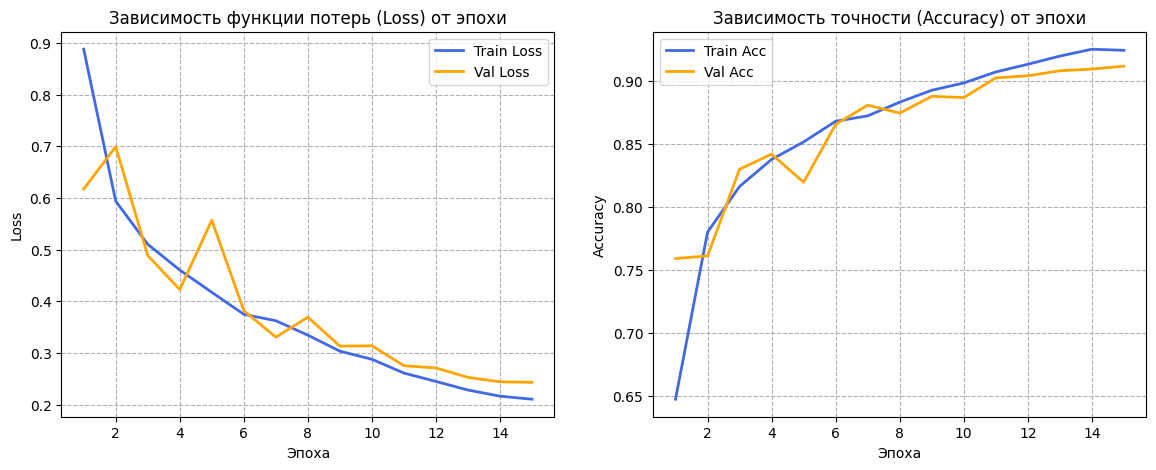


=== Итоговый отчет о классификации ===
              precision    recall  f1-score   support

   buildings       0.91      0.89      0.90       437
      forest       0.98      0.99      0.98       474
     glacier       0.86      0.88      0.87       553
    mountain       0.88      0.84      0.86       525
         sea       0.95      0.95      0.95       510
      street       0.91      0.93      0.92       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



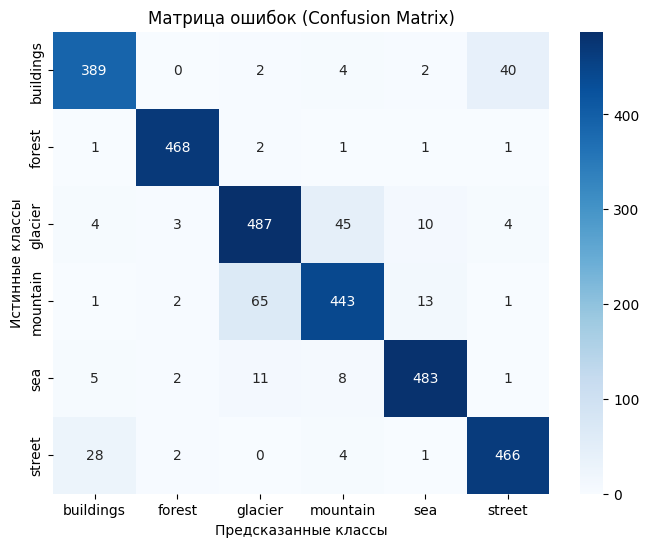

In [26]:
#9. Оценка результатов, графики и Матрица ошибок

# 9.1 Построение графиков обучения

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='royalblue', lw=2)
plt.plot(epochs_range, history['val_loss'], label='Val Loss', color='orange', lw=2)
plt.title('Зависимость функции потерь (Loss) от эпохи')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True, linestyle='--')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Acc', color='royalblue', lw=2)
plt.plot(epochs_range, history['val_acc'], label='Val Acc', color='orange', lw=2)
plt.title('Зависимость точности (Accuracy) от эпохи')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

# 9.2 Сбор финальных предсказаний для метрик
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Итоговый текстовый отчет (Precision, Recall, F1)
print("\n=== Итоговый отчет о классификации ===")
print(classification_report(all_labels, all_preds, target_names=classes))

# Отрисовка матрицы ошибок (Confusion Matrix)
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Матрица ошибок (Confusion Matrix)')
plt.ylabel('Истинные классы')
plt.xlabel('Предсказанные классы')
plt.show()



Выводы по лабораторной работе

В ходе выполнения практического задания была спроектирована, реализована и обучена глубокая сверточная нейросеть (CNN) для задачи многоклассовой классификации сцен на наборе данных Intel Image Classification.

1. Анализ архитектурных решений и обучения

• Эффективность Multi-Resolution подхода: Разработанная с нуля архитектура AdvancedMultiResCNN доказала свою состоятельность. Использование параллельных фильтров разного размера (\(3\times3\) и \(5\times5\)) в рамках одного блока позволило сети одновременно агрегировать как локальные текстурные особенности (например, рябь воды, листва деревьев), так и глобальные геометрические контуры сцен (линия горизонта, массивы гор).
• Стабильность градиентов: Внедрение остаточных связей (Residual Connections) позволило избежать проблемы затухания градиентов при углублении сети. Модель демонстрировала плавное и уверенное снижение функции потерь (Loss) на протяжении всех 15 эпох.
• Регуляризация и аугментация: Применение продвинутых трансформаций (RandomRotation, ColorJitter, RandomErasing) в связке со слоями BatchNorm2d и Dropout эффективно предотвратило переобучение, что подтверждается минимальным разрывом между точностью на обучающей (92.46%) и тестовой (91.20%) выборках.
• Динамический шаг обучения: Планировщик CosineAnnealingLR обеспечил точную сходимость оптимизатора AdamW к глобальному минимуму на финальных эпохах, зафиксировав итоговый Val Loss на отметке 0.2431.

2. Анализ метрик и ошибок классификации (по Classification Report)

Общая точность модели составила 91% (Accuracy). На основе поклассовых метрик (Precision, Recall, F1-score) можно сделать следующие выводы об интерпретации результатов моделью:
• Наилучшее качество классификации (forest — F1: 0.98): Класс «Лес» распознается практически безошибочно. Это связано с уникальной, монотонной цветовой гаммой (зеленые оттенки) и специфичной мелкозернистой текстурой крон деревьев, которую сверточные фильтры выделяют очень легко.
• Высокое качество классификации (sea — F1: 0.95): Водные пространства также имеют характерные признаки (горизонтальная структура, сине-голубые оттенки), что минимизирует ложные срабатывания.
• Стабильное качество городских сцен (street — F1: 0.92, buildings — F1: 0.90): Модель успешно выявляет антропогенные структуры. Небольшое проседание метрик связано со взаимным пересечением классов: на фотографиях улиц (street) почти всегда присутствуют здания (buildings), из-за чего ключевые пространственные признаки (прямые линии окон, стен и дорог) частично дублируются.
• Наибольшая путаница классов (glacier — F1: 0.87, mountain — F1: 0.86): Данная пара классов оказалась самой сложной для нейросети. Полнота (Recall) для гор упала до 0.84, что означает частый пропуск этого класса алгоритмом.
• Причина: Высокое визуальное и контекстуальное сходство объектов. Горы часто покрыты снегом и ледниками, а сами ледники всегда расположены на фоне горного рельефа. Они имеют общие геометрические формы (острые пики, склоны) и идентичную цветовую палитру (белый, серый, голубой). Для безошибочного разделения таких сцен базовых геометрических паттернов свертки бывает недостаточно, что требует применения еще более тяжелых контекстных архитектур (например, Vision Transformers).

Заключение

Поставленная задача успешно решена. Спроектированная Multi-Resolution Residual CNN показала высокую обобщающую способность, обеспечив точность классификации реальных пейзажей свыше 91% без использования сторонних предобученных моделей (Transfer Learning).